# 10 · Deep Q-networks

Every learner so far kept one number for each state-action pair. For a world of 42 cells that is
the right design. For a problem whose states cannot be listed, such as a board game, it is no
design at all, and the usual replacement is a neural network that computes action values from a
description of the state. This notebook makes that replacement on the grid worlds, where
everything a network produces can still be checked exactly, and asks two questions:

* **What does a network cost?** On the report's 7 × 8 world, a table and a network learn from the
  same kind of experience and are compared move for move.
* **What can a network do that a table cannot?** A table learned in one world says nothing about
  the next one. A network that reads the map might. It is trained on a stream of random worlds
  and scored on worlds it has never seen.

The notebook needs PyTorch (`pip install -e ".[deep]"`) and takes about seven minutes on two CPU
cores. Unlike the other notebooks, its numbers can change a little from one machine or PyTorch
version to the next, because network training is not reproducible to the last bit across them.
The sentences that quote numbers are produced by the code, so they stay in step with the run.

In [1]:
import time
from collections import deque

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display

import mdplab as ml
from mdplab import plotting as mp
from mdplab.dqn import QDenseNetwork, QMapNetwork, action_values, greedy_policy, train_dqn, train_on_sweeps
from mdplab.gridworld import FREE, GOAL

mp.use_style()
pd.options.display.float_format = "{:,.3f}".format
torch.set_num_threads(2)
torch.manual_seed(0)  # the networks below get their initial weights from this generator

world = ml.GridWorld.report_figure1()
mdp = world.mdp
scorer = ml.PolicyScorer(mdp)
notebook_start = time.perf_counter()

## One world: a network in place of the table

The setting is the online one of notebook 9. An agent starts each episode in a random cell of the
report's world, moves ϵ-greedily, and is stopped after 100 moves if it has not ended before.
ϵ falls from 1 to 0.1 over the first 60% of training. The table is plain Q-learning with a step
size of 0.1.

The network is given the map as three images (obstacles, pits, goal) and the agent's position as
a fourth. Three convolution layers and two dense layers turn them into four action values. It
learns from the same Q-learning target as the table, with the three additions that make up
**DQN**:

* **Experience replay.** Every move is stored. Each gradient step uses 128 moves drawn at random
  from the last 100,000, so consecutive, strongly related moves are not learned from in a row,
  and each move is used several times.
* **A target network.** The value of the next state in the learning target comes from a copy of
  the network that is refreshed only every 100 gradient steps. Otherwise every step would move
  the target it is aiming at.
* **The double-Q target.** The network being trained chooses the next action and the copy says
  what it is worth, which removes most of Q-learning's optimistic bias (the idea of Double
  Q-learning in notebook 9, at no extra cost here).

Rewards are divided by 200, so the network works with values between −1 and 1.

The network has **388,964 weights** where the table has 168 numbers. After 150,000 moves its greedy policy gives up **0.03** of value and picks an action that is not optimal in 4 of 42 cells; the ten tables give up 0.03 (median). In the second half of training the network's evaluations range from 0.03 to 166, the tables' median from 0.02 to 0.68. Training took **124 s** for the network (4,626 gradient steps) and 0.7 s per table, a factor of 171.

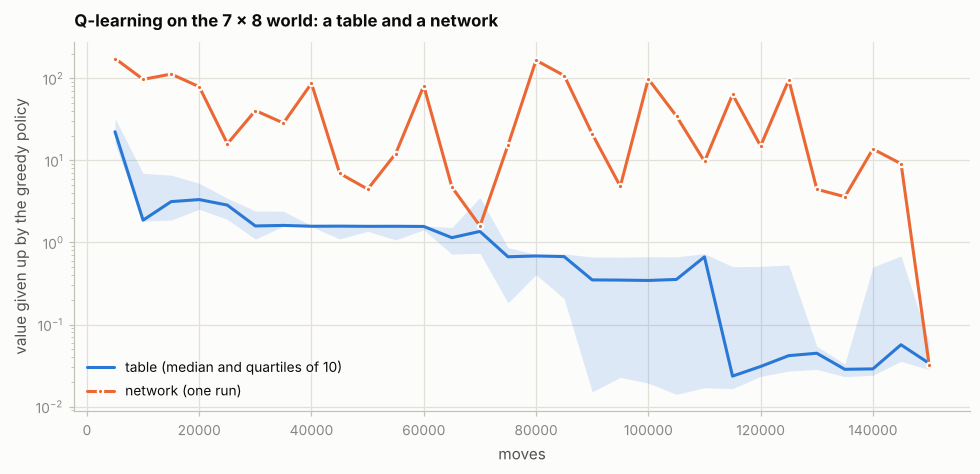

In [2]:
MOVES = 150_000


def value_given_up(net):
    """Exact value the network's greedy policy gives up on the report's world."""
    return float(scorer(action_values(net, world))["value_gap"][0])


dqn = train_dqn(lambda rng: world, MOVES, net=QDenseNetwork(*world.shape), resample=False,
                evaluate=value_given_up, eval_every=5_000, seed=0)

start = time.perf_counter()
tables = ml.td_control(mdp, MOVES, method="q_learning", epsilon=ml.linear_decay(1.0, 0.1, int(0.6 * MOVES)), alpha=0.1,
                       n_runs=10, seed=10, scorer=scorer, n_checkpoints=30, max_episode_steps=100)
table_seconds = (time.perf_counter() - start) / 10

fig, ax = plt.subplots(figsize=(8.8, 4.2))
mp.band(ax, tables.steps, np.maximum(tables.history["value_gap"], 1e-2), color=mp.SERIES[0], label="table (median and quartiles of 10)")
ax.plot(dqn.steps, np.maximum(dqn.scores, 1e-2), color=mp.SERIES[1], marker="o", ms=3.5, label="network (one run)")
ax.set(yscale="log", xlabel="moves", ylabel="value given up by the greedy policy", title="Q-learning on the 7 × 8 world: a table and a network")
ax.legend(loc="lower left")
mp.savefig(fig, "10_table_vs_network")

net_policy = greedy_policy(dqn.net, world)
net_wrong = world.free & ~scorer.optimal[np.arange(mdp.n_states), net_policy]
n_weights = sum(p.numel() for p in dqn.net.parameters())
second_half = np.array(dqn.scores[len(dqn.scores) // 2:])
display(Markdown(
    f"The network has **{n_weights:,} weights** where the table has {4 * world.free.sum()} numbers. "
    f"After {MOVES:,} moves its greedy policy gives up **{dqn.scores[-1]:.2f}** of value and picks an action that is not optimal in "
    f"{net_wrong.sum()} of {world.free.sum()} cells; the ten tables give up {np.median(tables.history['value_gap'][-1]):.2f} (median). "
    f"In the second half of training the network's evaluations range from {second_half.min():.2f} to {second_half.max():.0f}, "
    f"the tables' median from {np.median(tables.history['value_gap'], axis=1)[len(tables.steps) // 2:].min():.2f} to "
    f"{np.median(tables.history['value_gap'], axis=1)[len(tables.steps) // 2:].max():.2f}. "
    f"Training took **{dqn.seconds:.0f} s** for the network ({dqn.updates:,} gradient steps) and {table_seconds:.1f} s per table, "
    f"a factor of {dqn.seconds / table_seconds:,.0f}."
))

The two learners can end close together. They do not get there the same way. The tables improve
steadily and by the middle of the run give up about one unit of value or less. The network's
curve is erratic for almost the whole run: from one evaluation to the next, 5,000 moves apart,
its policy goes from giving up a few units of value to giving up half of it or more, and back.
Where it happens to stand when training stops is partly luck. When this notebook was being written, the
same code started from different random weights ended at 1.1 with seven cells wrong. One run of
a network is an anecdote, which is why the rest of this notebook scores networks on hundreds of
worlds and not on one curve.

Nothing else was to be expected on a world this small. A table has exactly one adjustable number
for each thing to be learned, and learning about one cell leaves all the others alone. Every
gradient step of the network moves all of its weights, so what it learns about one cell shifts
its values for the others. And the network costs a couple of hundred times the computing time.

The network's learning rate shrinks linearly to a tenth of its starting value during the run.
That is its version of the step-size schedules of notebook 5.

### How accurate are the network's values?

On values of up to 200, the network is off by **1.8** for a typical action (the median). The average error is 4.3 and the largest 44, because of the actions that risk a pit: those worth over 20 less than the best action of their cell are typically off by 13. The best action of a typical cell beats the second best by **2.0**, and in 40% of the cells by less than the network's typical error. The network's error in that margin itself is **0.5** (median), against 1.6 and 1.9 for the two values it is the difference of.

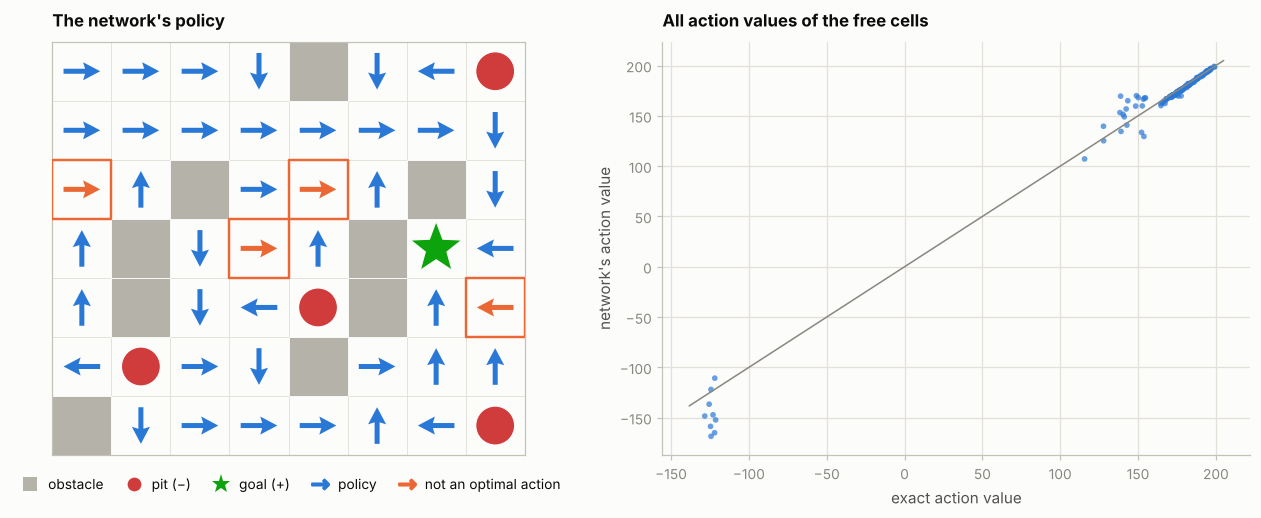

In [3]:
q_net = action_values(dqn.net, world) * world.goal_reward
exact, approx = scorer.Q_star[world.free], q_net[world.free]
error = np.abs(approx - exact)
order = np.argsort(exact, axis=1)
cell = np.arange(len(exact))
first, second = order[:, -1], order[:, -2]            # the best and the second-best action of each cell
margin = exact[cell, first] - exact[cell, second]
margin_error = np.abs((approx[cell, first] - approx[cell, second]) - margin)
risky = exact.max(axis=1, keepdims=True) - exact > 20  # worth far less than the cell's best action: only a pit does that
display(Markdown(
    f"On values of up to 200, the network is off by **{np.median(error):.1f}** for a typical action (the median). The average error is "
    f"{error.mean():.1f} and the largest {error.max():.0f}, because of the actions that risk a pit: those worth over 20 less than the best "
    f"action of their cell are typically off by {np.median(error[risky]):.0f}. "
    f"The best action of a typical cell beats the second best by **{np.median(margin):.1f}**, and in {np.mean(margin < np.median(error)):.0%} "
    f"of the cells by less than the network's typical error. "
    f"The network's error in that margin itself is **{np.median(margin_error):.1f}** (median), against "
    f"{np.median(error[cell, first]):.1f} and {np.median(error[cell, second]):.1f} for the two values it is the difference of."
))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))
mp.plot_gridworld(world, net_policy, flagged=net_wrong, ax=axes[0], title="The network's policy", flagged_label="not an optimal action")
ax = axes[1]
ax.scatter(scorer.Q_star[world.free].ravel(), q_net[world.free].ravel(), s=14, color=mp.SERIES[0], alpha=0.7, edgecolor="none")
lim = [scorer.Q_star[world.free].min() - 10, 205]
ax.plot(lim, lim, color=mp.MUTED, lw=1)
ax.set(xlabel="exact action value", ylabel="network's action value", title="All action values of the free cells")
mp.savefig(fig, "10_network_policy");

This is the difficulty that the rest of the notebook keeps running into. With a discount of 0.99,
taking one step longer to reach the goal lowers an action's value by 1%, about 2 out of 200. A
policy is read off the *differences* between the actions of a cell, and those differences are
about as large as the errors the network makes on the values themselves. A table's errors
shrink towards zero as the visits accumulate (notebook 5). A network's errors stop shrinking
where its fit stops improving.

The policy comes out right in most cells anyway because the errors of a cell's best and
second-best action mostly point the same way: their difference is known several times more
accurately than either value. The points far from the diagonal in the scatter plot are the
actions that risk a pit, which matter little for the policy as long as they stay far below the
others.

## Many worlds: reading the map

Now the question that a table cannot even be asked. The learner no longer gets one world. It gets
a new random 5 × 5 world every time, drawn the way the report draws them (each cell a pit or an
obstacle with probability 0.1, one goal), and it is scored on worlds that were kept out of
training.

**The score.** On each test world the network's greedy policy is evaluated exactly and compared
with the optimal policy. The value it gives up, averaged over the free cells, is divided by what
a policy that acts at random gives up: `score = 1 − loss / loss of random`, so 1 is optimal and 0
is as bad as random. `ml.WorldSet` solves every world once and does this bookkeeping. Since all
values are exact, a score has no sampling error beyond the choice of the test worlds.

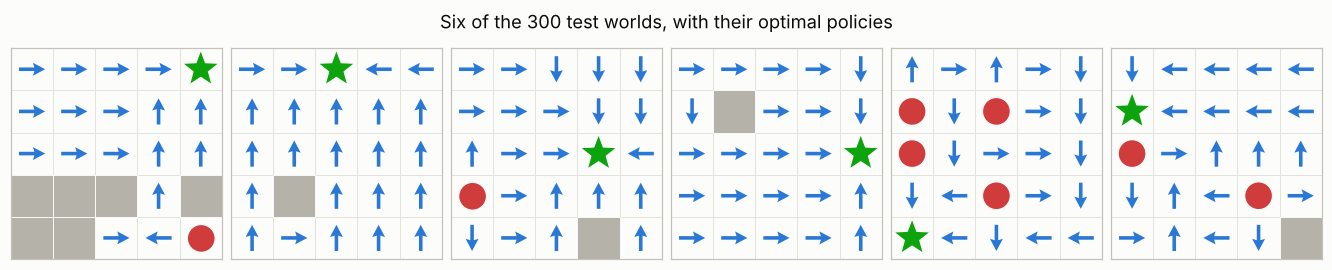

The 300 test worlds have 19.6 free cells on average. Under the optimal policy 95.7% of all starting cells lead to the goal and 1.4% end in a pit; the rest can do neither, because the goal is walled off from them.

In [4]:
SIZE = 5
validation = ml.WorldSet.random(SIZE, SIZE, n=50, seed=101)   # watched during training
unseen = ml.WorldSet.random(SIZE, SIZE, n=300, seed=202)      # looked at once training is over
held_out = {w.layout.tobytes() for w in validation.worlds + unseen.worlds}


def training_world(rng):
    """A random 5 × 5 world that is in neither the validation set nor the test set."""
    while True:
        candidate = ml.GridWorld.random(SIZE, SIZE, seed=rng)
        if candidate.layout.tobytes() not in held_out:
            return candidate


def score_on(worlds, net, depth=None):
    return worlds.evaluate(lambda w: greedy_policy(net, w, depth))


fig, axes = plt.subplots(1, 6, figsize=(12, 2.4))
for ax, w in zip(axes, unseen.worlds):
    mp.plot_gridworld(w, ml.policy_iteration(w.mdp).policy, ax=ax, legend=False)
fig.suptitle("Six of the 300 test worlds, with their optimal policies")
plt.show()
display(Markdown(
    f"The 300 test worlds have {unseen.optimal['free_cells'].mean():.1f} free cells on average. Under the optimal policy "
    f"{unseen.optimal['p_goal'].mean():.1%} of all starting cells lead to the goal and {unseen.optimal['p_pit'].mean():.1%} end in a pit; "
    f"the rest can do neither, because the goal is walled off from them."
))

Two changes make learning across worlds practical on a CPU.

**A network that returns a map.** `QMapNetwork` consists of convolution layers only. It is shown
the three images of the map and returns four action values *for every cell*; the values for an
agent standing on a cell are read off at that cell. One pass through the network therefore
evaluates every position of a world, and nothing in it depends on the size of the map. The edge
of the world is drawn as a ring of obstacles, since bumping into either has the same effect. With
six layers, a cell's values can depend on the map up to six cells away, which covers a 5 × 5
world from any cell.

**Sweeps instead of episodes.** With every cell's values available at once, the natural
experience is the uniform sweep of notebook 3: one sampled move from every free cell for each of
the four actions. Each update draws 32 new worlds, samples such a sweep in each of them (about
2,500 moves) and takes one gradient step on all of it. This is still learning from sampled moves
alone. Because every batch is fresh and unrelated to the last, the replay memory is not needed;
the target network and the double-Q target stay.

### Which discount should the learner use?

The worlds are judged with the report's discount of 0.99. Nothing forces the learner to use the
same discount in its own targets, and after what the single world showed about differences of 1%
there is a reason to try shorter horizons. Four networks are trained, identical except for the
discount in their learning target. Next to each, a planner shows what that discount costs in
principle: the exactly optimal policy for the lower discount, judged at 0.99 like everything else.

In [5]:
GAMMAS = [0.8, 0.9, 0.95, 0.99]
UPDATES = 3_000
learned, tested = {}, {}
for gamma in GAMMAS:
    run = train_on_sweeps(training_world, UPDATES, net=QMapNetwork(), gamma=gamma, seed=1,
                          evaluate=lambda net: score_on(validation, net)["score"].mean(), eval_every=250)
    learned[gamma], tested[gamma] = run, score_on(unseen, run.net)
    print(f"discount {gamma}: trained in {run.seconds:.0f} s")

planned = {gamma: unseen.evaluate(lambda w, g=gamma: ml.policy_iteration(w.replace(gamma=g).mdp).policy) for gamma in GAMMAS}
moves_per_update = 32 * 4 * unseen.optimal["free_cells"].mean()

discount 0.8: trained in 29 s


discount 0.9: trained in 29 s


discount 0.95: trained in 30 s


discount 0.99: trained in 30 s


Learning with the discount it is judged by, the network scores **0.62**. With the three shorter horizons it scores between 0.90 and 0.91, best with 0.95. Each network saw 7.5 million sampled moves in 96,000 worlds.

,planner: score,planner: ends in a pit,network: score,network: ends in a pit,network: reaches the goal
discount,,,,,
0.800,0.960,0.052,0.900,0.081,0.889
0.900,0.970,0.047,0.902,0.077,0.895
0.950,0.981,0.039,0.909,0.058,0.907
0.990,1.000,0.014,0.616,0.024,0.856


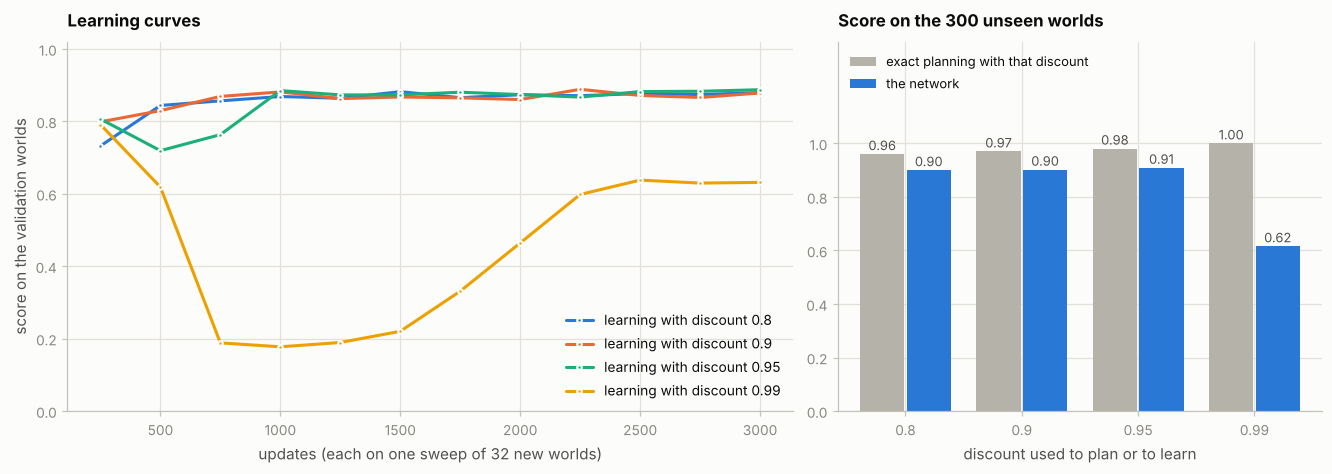

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
for gamma, colour in zip(GAMMAS, mp.SERIES):
    ax.plot(learned[gamma].steps, learned[gamma].scores, color=colour, marker="o", ms=3, label=f"learning with discount {gamma}")
ax.set(xlabel="updates (each on one sweep of 32 new worlds)", ylabel="score on the validation worlds", ylim=(0, 1.02),
       title="Learning curves")
ax.legend(loc="lower right")

ax = axes[1]
x = np.arange(len(GAMMAS))
ax.bar(x - 0.2, [planned[g]["score"].mean() for g in GAMMAS], width=0.38, color=mp.GREY, label="exact planning with that discount")
ax.bar(x + 0.2, [tested[g]["score"].mean() for g in GAMMAS], width=0.38, color=mp.SERIES[0], label="the network")
for i, g in enumerate(GAMMAS):
    ax.text(i - 0.2, planned[g]["score"].mean() + 0.015, f"{planned[g]['score'].mean():.2f}", ha="center", fontsize=8.5, color=mp.INK_SECONDARY)
    ax.text(i + 0.2, tested[g]["score"].mean() + 0.015, f"{tested[g]['score'].mean():.2f}", ha="center", fontsize=8.5, color=mp.INK_SECONDARY)
ax.set(xticks=x, xticklabels=[str(g) for g in GAMMAS], xlabel="discount used to plan or to learn", ylim=(0, 1.38),
       yticks=[0, 0.2, 0.4, 0.6, 0.8, 1.0], title="Score on the 300 unseen worlds")
ax.legend(loc="upper left", fontsize=8.5)
mp.savefig(fig, "10_which_discount")

summary = pd.DataFrame({
    "planner: score": {g: planned[g]["score"].mean() for g in GAMMAS},
    "planner: ends in a pit": {g: planned[g]["p_pit"].mean() for g in GAMMAS},
    "network: score": {g: tested[g]["score"].mean() for g in GAMMAS},
    "network: ends in a pit": {g: tested[g]["p_pit"].mean() for g in GAMMAS},
    "network: reaches the goal": {g: tested[g]["p_goal"].mean() for g in GAMMAS},
})
summary.index.name = "discount"
best_gamma = max(GAMMAS, key=lambda g: tested[g]["score"].mean())
others = [tested[g]["score"].mean() for g in GAMMAS if g != 0.99]
display(Markdown(
    f"Learning with the discount it is judged by, the network scores **{tested[0.99]['score'].mean():.2f}**. With the three shorter "
    f"horizons it scores between {min(others):.2f} and {max(others):.2f}, best with {best_gamma}. "
    f"Each network saw {UPDATES * moves_per_update / 1e6:.1f} million sampled moves in {UPDATES * 32:,} worlds."
))
summary

For the planner the shorter horizon is a pure handicap. Its score falls as the discount falls,
because an impatient planner cuts corners next to pits, and the table shows it ending in a pit
several times as often. For the learner the shorter horizon is what makes learning work. The
network that uses 0.99 does worst by a wide margin, and its learning curve is the odd one out:
it starts like the others, collapses within the first thousand updates, and recovers only
partly as the learning rate becomes small.

The single world suggested why, and the suggestion can be checked on the four networks directly.
Each one's values are compared with the exact optimal values *for its own discount*, and the
error is set against the difference between the best and the second-best action that it has to
resolve.

In [7]:
rows = {}
for gamma in GAMMAS:
    errors, margins = [], []
    for w in unseen.worlds:
        model = w.replace(gamma=gamma).mdp
        exact = model.q_values(ml.policy_iteration(model).V)[w.free] / w.goal_reward
        errors.append(np.abs(action_values(learned[gamma].net, w)[w.free] - exact).ravel())
        ranked = np.sort(exact, axis=1)
        margins.append(ranked[:, -1] - ranked[:, -2])
    errors, margins = np.concatenate(errors), np.concatenate(margins)
    rows[gamma] = {
        "typical error of the network's values": np.median(errors),
        "typical margin of the best action": np.median(margins),
        "cells whose margin is below the typical error": np.mean(margins < np.median(errors)),
        "optimal action chosen": 1 - tested[gamma]["wrong_cells"].mean(),
    }
precision = pd.DataFrame(rows).T
precision.index.name = "discount"
low, high = precision.iloc[0], precision.iloc[-1]
display(Markdown(
    f"The networks' typical errors are between {precision.iloc[:, 0].min():.3f} and {precision.iloc[:, 0].max():.3f} of the goal's reward "
    f"whatever the discount. The margins are not alike: {low.iloc[1]:.3f} with a discount of {GAMMAS[0]} and {high.iloc[1]:.3f} with {GAMMAS[-1]}. "
    f"With {GAMMAS[-1]}, the best action leads by less than the network's typical error in **{high.iloc[2]:.0%}** of all cells; with {GAMMAS[0]}, in {low.iloc[2]:.0%}."
))
precision

The networks' typical errors are between 0.025 and 0.037 of the goal's reward whatever the discount. The margins are not alike: 0.058 with a discount of 0.8 and 0.009 with 0.99. With 0.99, the best action leads by less than the network's typical error in **78%** of all cells; with 0.8, in 34%.

,typical error of the network's values,typical margin of the best action,cells whose margin is below the typical error,optimal action chosen
discount,,,,
0.800,0.025,0.058,0.341,0.711
0.900,0.032,0.047,0.411,0.709
0.950,0.037,0.035,0.542,0.725
0.990,0.029,0.009,0.782,0.592


Values are in units of the goal's reward, and "typical" is the median over all cells of the 300
test worlds. The network fits the values about equally well for every discount. What changes is
how well it has to fit them: the shorter the horizon, the more one step of delay matters, and
the further apart the actions of a cell lie. With 0.99 the network is asked to resolve
differences that are a third of its error.

The last column, like the scores, measures against the policy that is optimal for 0.99. That is
why 0.8 and 0.95 come out alike: the shorter horizon is easier to learn and aims at a slightly
different target. The 0.99 network is the most careful of the four about pits (large
differences, which it resolves) and the worst at finding the way (small ones, which it cannot):
it ends in a pit least often and reaches the goal least often.

Planning or learning with a lower discount than the one that defines the task is an old idea
(Petrik and Scherrer, 2008), and the smallness of the differences between actions is known as
the action-gap problem (Bellemare et al., 2016). In notebook 7 the discount was part of the
problem. Here it has become a setting of the learner.

### A closer look at the best network

On the 300 unseen worlds the network trained with discount 0.95 scores **0.909** on average (median 0.944). It is above 0.99 on 12% of the worlds and below 0.8 on 11%. It chooses an optimal action in 72% of all cells, reaches the goal from 90.7% of them (optimal: 95.7%) and ends in a pit from 5.8% (optimal: 1.4%).

,worlds,network's score,"planner's score, same discount",optimal action chosen,ends in a pit,ends in a pit (optimal policy)
a shortest path is open from every cell,103,0.961,0.986,0.765,0.025,0.003
some cells are walled off from the goal,65,0.886,0.982,0.747,0.112,0.043
some cells must go around something,132,0.879,0.976,0.683,0.057,0.009


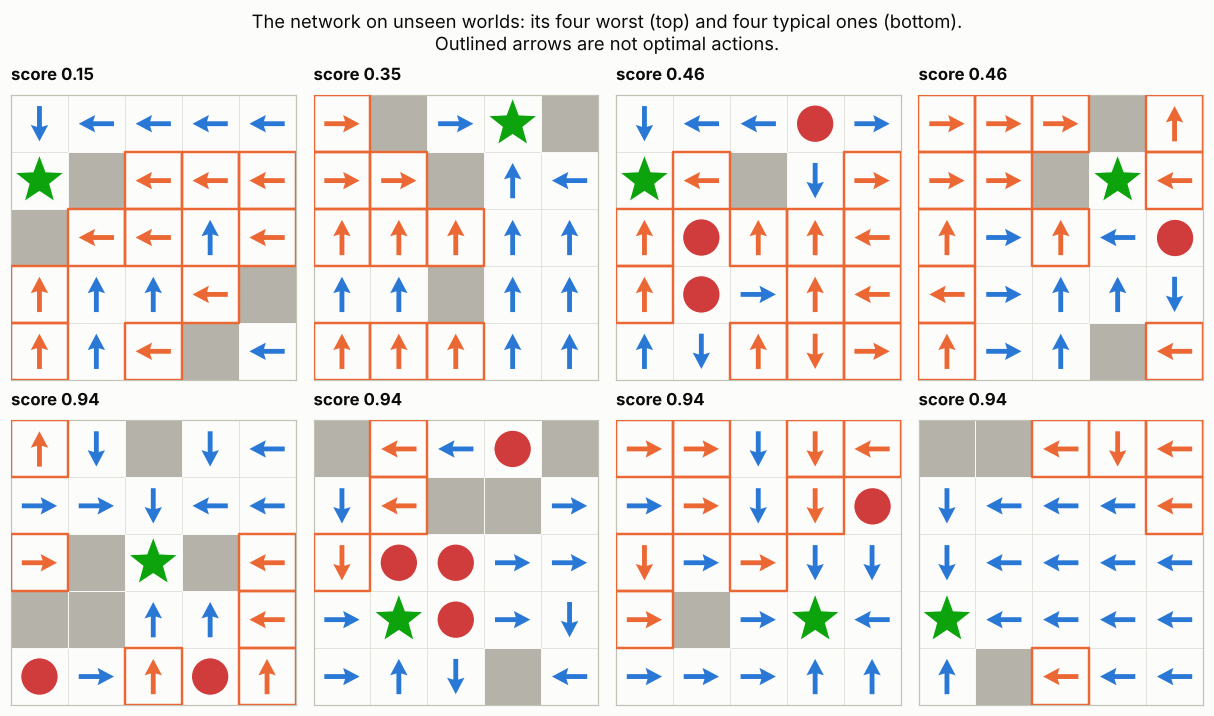

In [8]:
net = learned[best_gamma].net
result = tested[best_gamma]


def steps_to_goal(w):
    """Length of the shortest path through free cells to the goal, from every cell (inf if there is none)."""
    rows_, cols_ = w.shape
    dist = np.full((rows_, cols_), np.inf)
    (start_cell,) = np.argwhere(w.layout == GOAL)
    dist[tuple(start_cell)] = 0
    queue = deque([tuple(start_cell)])
    while queue:
        r, c = queue.popleft()
        for dr, dc in ((-1, 0), (1, 0), (0, -1), (0, 1)):
            r2, c2 = r + dr, c + dc
            if 0 <= r2 < rows_ and 0 <= c2 < cols_ and w.layout[r2, c2] == FREE and np.isinf(dist[r2, c2]):
                dist[r2, c2] = dist[r, c] + 1
                queue.append((r2, c2))
    return dist.ravel()


def kind_of_world(w):
    dist = steps_to_goal(w)[w.free]
    (goal_cell,) = np.argwhere(w.layout == GOAL)
    straight = np.abs(np.argwhere(w.layout == FREE) - goal_cell).sum(axis=1)
    if np.isinf(dist).any():
        return "some cells are walled off from the goal"
    if (dist > straight).any():
        return "some cells must go around something"
    return "a shortest path is open from every cell"


kinds = pd.Series([kind_of_world(w) for w in unseen.worlds])
by_kind = pd.DataFrame({
    "worlds": kinds.value_counts(),
    "network's score": result["score"].groupby(kinds).mean(),
    "planner's score, same discount": planned[best_gamma]["score"].groupby(kinds).mean(),
    "optimal action chosen": 1 - result["wrong_cells"].groupby(kinds).mean(),
    "ends in a pit": result["p_pit"].groupby(kinds).mean(),
    "ends in a pit (optimal policy)": unseen.optimal["p_pit"].groupby(kinds).mean(),
}).sort_values("network's score", ascending=False)

order = np.argsort(result["score"].to_numpy())
shown = list(order[:4]) + list(order[len(order) // 2 - 2: len(order) // 2 + 2])
fig, axes = plt.subplots(2, 4, figsize=(11, 6.4))
for ax, i in zip(axes.ravel(), shown):
    w = unseen.worlds[i]
    policy = greedy_policy(net, w)
    wrong = w.free & ~ml.optimal_actions(w.mdp, ml.policy_iteration(w.mdp).V)[np.arange(w.n_states), policy]
    mp.plot_gridworld(w, policy, flagged=wrong, ax=ax, legend=False, title=f"score {result['score'][i]:.2f}")
fig.suptitle("The network on unseen worlds: its four worst (top) and four typical ones (bottom).\nOutlined arrows are not optimal actions.")
mp.savefig(fig, "10_unseen_worlds")

display(Markdown(
    f"On the 300 unseen worlds the network trained with discount {best_gamma} scores **{result['score'].mean():.3f}** on average "
    f"(median {result['score'].median():.3f}). It is above 0.99 on {np.mean(result['score'] > 0.99):.0%} of the worlds and below 0.8 on "
    f"{np.mean(result['score'] < 0.8):.0%}. It chooses an optimal action in {1 - result['wrong_cells'].mean():.0%} of all cells, "
    f"reaches the goal from {result['p_goal'].mean():.1%} of them (optimal: {unseen.optimal['p_goal'].mean():.1%}) "
    f"and ends in a pit from {result['p_pit'].mean():.1%} (optimal: {unseen.optimal['p_pit'].mean():.1%})."
))
by_kind

The network has learned a good deal of what the three images mean: it heads for the goal and
mostly keeps away from the pits. What it has not learned is to plan a route. In its worst worlds
the goal lies behind obstacles as seen from many cells, and the network's arrows point at it
straight through them. The table says the same for all 300 worlds. Where a shortest path to the
goal is open from every cell, the network comes within a few hundredths of a planner that uses
the same discount. Where some cells have to go around something, or cannot reach the goal at
all, it falls well short of it. Cells that are walled off from the goal are a case of their
own: the best an agent can do there is to stay clear of the pits for ever, and the network ends
in one much more often than it has to.

### What does the network save?

The network produces a policy for a new world without making a single move in it. The fair
comparison is with a learner that starts from nothing in each new world: a fresh table, given
sweeps of experience in that world and the good step size of notebook 5 (1/n<sup>0.7</sup>).

A fresh table has caught up with the network's score (0.911 on these worlds) after **10 sweeps**, about 790 moves. After 1,000 sweeps it scores 1.000. The network was trained on 7.5 million moves.

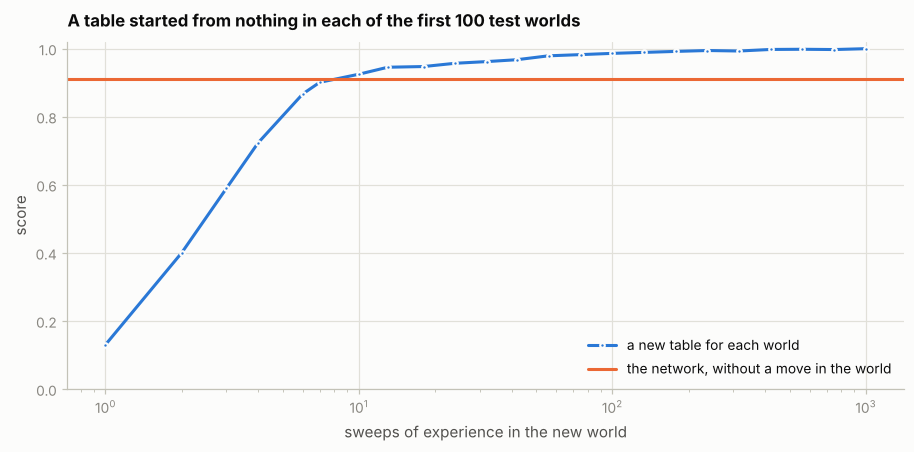

In [9]:
N_TABLES, SWEEPS = 100, 1_000
table_scores = []
for i in range(N_TABLES):
    w = unseen.worlds[i]
    run = ml.synchronous_q_learning(w.mdp, SWEEPS, alpha=ml.polynomial(0.7), n_runs=1, seed=i, scorer=ml.PolicyScorer(w.mdp), n_checkpoints=25)
    table_scores.append(1 - run.history["value_gap"][:, 0] / unseen.optimal["lost_by_random"][i])
table_scores, sweeps = np.array(table_scores).mean(axis=0), run.steps
net_level = result["score"][:N_TABLES].mean()
catch_up = int(sweeps[np.argmax(table_scores >= net_level)])
moves_per_sweep = 4 * unseen.optimal["free_cells"][:N_TABLES].mean()

fig, ax = plt.subplots(figsize=(8.2, 4))
ax.plot(sweeps, table_scores, color=mp.SERIES[0], marker="o", ms=3, label="a new table for each world")
ax.axhline(net_level, color=mp.SERIES[1], label="the network, without a move in the world")
ax.set(xscale="log", xlabel="sweeps of experience in the new world", ylabel="score", ylim=(0, 1.02),
       title=f"A table started from nothing in each of the first {N_TABLES} test worlds")
ax.legend(loc="lower right")
mp.savefig(fig, "10_table_catches_up")
display(Markdown(
    f"A fresh table has caught up with the network's score ({net_level:.3f} on these worlds) after **{catch_up} sweeps**, "
    f"about {catch_up * moves_per_sweep:,.0f} moves. After {SWEEPS:,} sweeps it scores {table_scores[-1]:.3f}. "
    f"The network was trained on {UPDATES * moves_per_update / 1e6:.1f} million moves."
))

On worlds of 25 cells the network's head start is worth about ten sweeps, which is a few hundred
moves. After that the table is ahead, and it goes on to the exact optimum, which the network
never reaches. Against that stand the millions of moves that training
the network consumed. For worlds this small, starting a new table in every world remains the
better tool, and planning (notebook 8) a better one still.

The balance tips where a table stops being possible: when there are too many states to list, or
when no state is ever met twice. There the alternative to a network is no policy at all, and the
properties measured here are what one has to live with.

## A network shaped like value iteration

The six layers of the map network are six different computations applied once each. Value
iteration is one local computation applied again and again, as often as the world requires. A
network can be given that shape: all layers after the first share one set of weights, and each
application is shown the map again so that it cannot be forgotten on the way. The idea goes back
to value iteration networks (Tamar et al., 2016). Below, the shared update is applied 16 times
during training. The number of applications is not part of the weights, so it can be changed
when the network is used.

With 11,140 weights against 47,268, the network with the shared update scores **0.905** on the unseen 5 × 5 worlds; the one with six separate layers scored 0.909. Training took 106 s. The score is highest with 16 applications for worlds of every size; with 64 applications it is down to 0.47 on the 5 × 5 worlds.

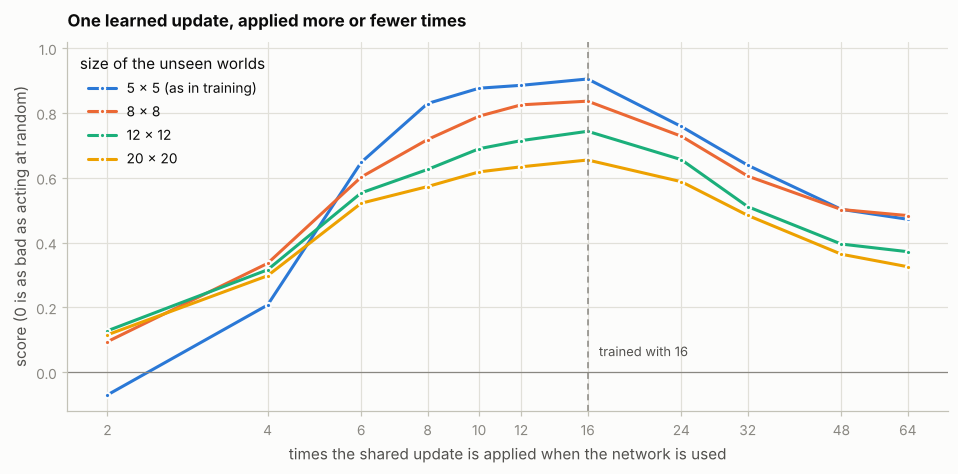

In [10]:
DEPTH = 16
tied = train_on_sweeps(training_world, 4_000, net=QMapNetwork(depth=DEPTH, tied=True), gamma=best_gamma, seed=1,
                       evaluate=lambda net: score_on(validation, net)["score"].mean(), eval_every=500)
tied_result = score_on(unseen, tied.net)

bigger = {
    "5 × 5 (as in training)": unseen,
    "8 × 8": ml.WorldSet.random(8, 8, n=100, seed=303),
    "12 × 12": ml.WorldSet.random(12, 12, n=50, seed=404),
    "20 × 20": ml.WorldSet.random(20, 20, n=20, seed=505),
}
depths = [2, 4, 6, 8, 10, 12, 16, 24, 32, 48, 64]
by_depth = {name: [score_on(ws, tied.net, d)["score"].mean() for d in depths] for name, ws in bigger.items()}

fig, ax = plt.subplots(figsize=(8.6, 4.2))
for (name, scores), colour in zip(by_depth.items(), mp.SERIES):
    ax.plot(depths, scores, color=colour, marker="o", ms=3.5, label=name)
ax.axvline(DEPTH, color=mp.MUTED, lw=1, ls=(0, (4, 3)))
ax.text(DEPTH * 1.05, 0.05, f"trained with {DEPTH}", fontsize=8.5, color=mp.INK_SECONDARY)
ax.axhline(0, color=mp.MUTED, lw=0.8)
ax.set(xscale="log", xlabel="times the shared update is applied when the network is used", ylabel="score (0 is as bad as acting at random)",
       ylim=(min(min(scores) for scores in by_depth.values()) - 0.05, 1.02), title="One learned update, applied more or fewer times")
ax.set_xticks(depths, [str(d) for d in depths])
ax.minorticks_off()
ax.legend(loc="upper left", title="size of the unseen worlds")
mp.savefig(fig, "10_iterations")

peak = {name.split(" (")[0]: depths[int(np.argmax(scores))] for name, scores in by_depth.items()}
peaks = (f"{depths[int(np.argmax(by_depth['8 × 8']))]} applications for worlds of every size" if len(set(peak.values())) == 1
         else ", ".join(f"{d} applications on {name} worlds" for name, d in peak.items()))
display(Markdown(
    f"With {sum(p.numel() for p in tied.net.parameters()):,} weights against {sum(p.numel() for p in net.parameters()):,}, the network with the "
    f"shared update scores **{tied_result['score'].mean():.3f}** on the unseen 5 × 5 worlds; the one with six separate layers scored "
    f"{result['score'].mean():.3f}. Training took {tied.seconds:.0f} s. "
    f"The score is highest with {peaks}; with {depths[-1]} applications it is down to {by_depth['5 × 5 (as in training)'][-1]:.2f} on the 5 × 5 worlds."
))

With a quarter of the weights, one shared update does about as well as six separate layers. And
up to a point it behaves the way an iteration should: every further application improves the
policy, in worlds of every size, up to the 16 applications it was trained with.

Beyond that the score falls again where a sweep of value iteration would settle. What the network
has learned is a computation of 16 steps, not an update that can be repeated until nothing
changes. Getting a network of this kind to keep improving when it is run for longer than in
training takes further measures during training (Schwarzschild et al., 2021; Bansal et al.,
2022), which are not attempted here.

### Worlds of other sizes

Neither network depends on the size of the map, so both can be put into worlds they were not
trained for, including the report's own.

In [11]:
bigger["the report's 7 × 8 world"] = ml.WorldSet([world])
transfer = {}
for name, ws in bigger.items():
    a, b = score_on(ws, net), score_on(ws, tied.net)
    transfer[name] = {
        "worlds": len(ws),
        "score: six layers": a["score"].mean(), "score: shared update": b["score"].mean(),
        "goal: six layers": a["p_goal"].mean(), "goal: shared update": b["p_goal"].mean(), "goal: optimal": ws.optimal["p_goal"].mean(),
        "pit: six layers": a["p_pit"].mean(), "pit: shared update": b["p_pit"].mean(), "pit: optimal": ws.optimal["p_pit"].mean(),
    }
transfer = pd.DataFrame(transfer).T.astype({"worlds": int})

records = []
for w in bigger["12 × 12"].worlds:
    best_actions = ml.optimal_actions(w.mdp, ml.policy_iteration(w.mdp).V)
    dist = steps_to_goal(w)
    cells = np.flatnonzero(w.free & np.isfinite(dist))
    records.append(pd.DataFrame({"who": "an action picked at random", "steps": dist[cells], "optimal": best_actions[cells].mean(axis=1)}))
    for label, n in (("six layers", net), ("shared update", tied.net)):
        records.append(pd.DataFrame({"who": label, "steps": dist[cells], "optimal": best_actions[cells, greedy_policy(n, w)[cells]]}))
records = pd.concat(records)
records["steps to the goal"] = pd.cut(records["steps"], [0, 3, 6, 9, 12, 1000], labels=["1 to 3", "4 to 6", "7 to 9", "10 to 12", "13 or more"])
by_distance = records.pivot_table(index="who", columns="steps to the goal", values="optimal", aggfunc="mean", observed=True)
by_distance = by_distance.loc[["six layers", "shared update", "an action picked at random"]]
by_distance.index.name = "share of cells with an optimal action (12 × 12 worlds)"
display(transfer)
by_distance

,worlds,score: six layers,score: shared update,goal: six layers,goal: shared update,goal: optimal,pit: six layers,pit: shared update,pit: optimal
5 × 5 (as in training),300,0.909,0.905,0.907,0.908,0.957,0.058,0.056,0.014
8 × 8,100,0.816,0.837,0.778,0.815,0.932,0.105,0.113,0.021
12 × 12,50,0.699,0.744,0.625,0.720,0.957,0.108,0.162,0.021
20 × 20,20,0.627,0.655,0.445,0.551,0.968,0.322,0.324,0.025
the report's 7 × 8 world,1,0.621,0.717,0.787,0.894,1.000,0.000,0.003,0.000


steps to the goal,1 to 3,4 to 6,7 to 9,10 to 12,13 or more
share of cells with an optimal action (12 × 12 worlds),,,,,
six layers,0.817,0.683,0.495,0.450,0.412
shared update,0.789,0.704,0.602,0.502,0.480
an action picked at random,0.250,0.250,0.250,0.250,0.251


Both networks lose quality as the worlds grow. The shared update loses somewhat less, and it does
better on the report's world, which neither has trained on. But neither is fit for use outside
the size it was trained on: in the 20 × 20 worlds about a third of all starting cells end in a
pit under either network, where the optimal policy loses a fortieth.

The second table shows where the quality goes. The further a cell is from the goal, the less
often a network picks an optimal action there, down to under half of the cells at 13 steps or
more (a random choice is right in a quarter). In 5 × 5 worlds the goal is rarely far away, so
distant goals are something neither network has had to deal with, and the one with six layers
often cannot even see them.

## Summary

* **On one small world a network buys nothing.** It can end with as good a policy as the table,
  at a couple of hundred times the computing cost, by way of an erratic learning curve, and with
  an outcome that depends on its random initial weights.
* **The obstacle is precision.** With a discount of 0.99, the actions of a cell differ by about
  1% of their value, and the network's values are off by about as much. A table's errors go to
  zero; a network's do not.
* **Learn with a shorter horizon than you are judged by.** Across random worlds, a network that
  learns with a discount of 0.8, 0.9 or 0.95 scores about 0.9 when judged at 0.99. One that
  learns with 0.99 itself scores about 0.6. A planner would lose only two to four hundredths from
  the shorter horizon.
* **Generalisation is real and partial.** A network trained on a stream of random 5 × 5 worlds
  produces, for a world it has never seen, a policy about nine tenths of the way from random to
  optimal without a single move in that world. It reads pits and the direction of the goal. It
  does not plan routes around obstacles.
* **The head start is small where a table is possible.** A fresh table catches up after about
  ten sweeps of a new world and then overtakes. A network earns its cost only where no table can
  be built.
* **A shared, repeated update** matches separate layers with a quarter of the weights and carries
  over to larger worlds a little better, but it stops improving at the number of repetitions it
  was trained with, and neither network is usable on worlds much larger than those it learned in.

### Where this leads

The natural sequel is a problem where the table is not an option. 4 × 4 × 4 tic-tac-toe (Qubic)
has 64 cells, 76 winning lines and at most 3<sup>64</sup> ≈ 3.4 × 10<sup>30</sup> ways to fill
the board. It is known to be a win for the first player (Patashnik, 1980), by a proof that took
a great deal of computer search; a table over its positions is out of the question. Much of this
notebook carries over to a learner for it: a network in place of the table, a slowly moving learning target, erratic progress that
has to be measured often and on many positions, and the value of checking against exact answers
wherever they exist. What is new there is the opponent. The value of a move depends on the reply,
and the experience usually comes from playing against oneself. That is a project of its own.

**References.** V. Mnih et al., "Human-level control through deep reinforcement learning",
*Nature* 518, 2015 (DQN). H. van Hasselt, A. Guez and D. Silver, "Deep reinforcement learning
with double Q-learning", AAAI 2016. M. Petrik and B. Scherrer, "Biasing approximate dynamic
programming with a lower discount factor", NIPS 2008. M. Bellemare et al., "Increasing the action
gap: new operators for reinforcement learning", AAAI 2016. A. Tamar et al., "Value iteration
networks", NIPS 2016. A. Schwarzschild et al., "Can you learn an algorithm? Generalizing from
easy to hard problems with recurrent networks", NeurIPS 2021. A. Bansal et al., "End-to-end
algorithm synthesis with recurrent networks: logical extrapolation without overthinking",
NeurIPS 2022. O. Patashnik, "Qubic: 4 × 4 × 4 tic-tac-toe", *Mathematics Magazine* 53, 1980.

Back to the [overview](../README.md).

In [12]:
print(f"notebook ran in {time.perf_counter() - notebook_start:.0f} s")

notebook ran in 401 s
